# HW4 research — HMM regimes on the S&P 500

This notebook is the research part of **strategy 2**. It studies two
**independent samples**:

1. **Volume-bar sample** — price + volume → 90-session median volume, `5 x median` bucket → bar log returns → 3-state HMM.
2. **Daily FFD sample** — daily log price → fractional differentiation → 3-state HMM on daily observations.

The samples are deliberately not merged. The FFD study is not aggregated into
the volume bars, and the volume bars are not filtered by the FFD warm-up.
They share only the underlying market history and the forward-return
evaluation.

Every HMM fit is walk-forward: the model at observation `t` sees only
observations before `t`.

## Homework data window

This notebook follows the HW4 chronology exactly:

- **Development:** 2010-01-01 through 2015-12-31. All research, fitting, validation, plots, and saved research states are restricted to this window.
- **Buffer / embargo:** 2016-01-01 through 2016-03-31. It is **not loaded** and is not used for fitting or research.
- **Final test:** 2016-04-01 onward. It is reserved for the frozen-model evaluation and is **not loaded** here.

Data before 2010 is used only for volume-bar and FFD lookbacks and HMM warm-up. No row dated 2016-01-01 or later is read by this notebook. Forward 90-day returns near 2015-12-31 are intentionally undefined because the buffer is excluded.

## Structural correction notice — November 13, 2026

Forward-return diagnostics now measure next-session entry through the first
session on/after entry + 90 calendar days. Incomplete horizons remain missing.
Market proxies use the benchmark calendar, quarantine invalid quotes before
return lags, and exclude cross-gap moves from daily returns. Existing research
CSVs predate these corrections and must be regenerated before interpretation;
see `research_outputs/README.md`. No final-period portfolio backtest was run
as part of this correction pass.


In [1]:
from pathlib import Path
import json
import sys
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning, module="hmmlearn")

root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists())
submission = root / "Homeworks/HW4/David_MartinsHuber"
if str(submission) not in sys.path:
    sys.path.insert(0, str(submission))

from research import (
    ResearchConfig,
    build_market_series,
    forward_return,
    run_market,
    state_summary,
    transition_matrix,
)
from research.bars import volume_bars
from research.fracdiff import ffd, ffd_weights, select_d

DATABASE = submission / "data/equities_top2000.duckdb"
END = "2015-12-31"
DEVELOPMENT_START = "2010-01-01"
DEVELOPMENT_END = "2015-12-31"
BUFFER_START = "2016-01-01"
BUFFER_END = "2016-03-31"
FINAL_TEST_START = "2016-04-01"
CONFIG = ResearchConfig()
OUTPUT = submission / "research_outputs"
OUTPUT.mkdir(exist_ok=True)

pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 30)


def development(result):
    """Restrict a walk-forward result to the HW4 development window."""
    index = result.states.index
    mask = ((index >= pd.Timestamp(DEVELOPMENT_START))
            & (index <= pd.Timestamp(DEVELOPMENT_END)))
    return result.__class__(
        states=result.states.loc[mask],
        probabilities=result.probabilities.loc[mask],
        versions=result.versions.loc[mask],
        feature=result.feature.loc[mask],
        fits=result.fits,
        d=None if result.d is None else result.d.loc[mask],
    )


print(CONFIG)
print("database:", DATABASE)
print("research cutoff:", END)
print("development window:", DEVELOPMENT_START, "to", DEVELOPMENT_END)
print("excluded buffer:", BUFFER_START, "to", BUFFER_END)
print("reserved final test:", FINAL_TEST_START, "onward")

ResearchConfig(median_window=90, bucket_multiple=5.0, volume_min_train=250, volume_refit_every=13, ffd_min_train=504, ffd_refit_every=63, ffd_d_refit_every=252, n_states=3, n_init=3, seed=7, n_iter=200, ffd_threshold=1e-05, ffd_pvalue=0.05, ffd_d_grid=(0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0))
database: /Users/davidhuber/Desktop/berkeley prequesites/Preprogram/UCB-MFE-python-preprogram-2026-winter/Homeworks/HW4/David_MartinsHuber/data/equities_top2000.duckdb
research cutoff: 2015-12-31
development window: 2010-01-01 to 2015-12-31
excluded buffer: 2016-01-01 to 2016-03-31
reserved final test: 2016-04-01 onward


## 1. Data and volume proxies

`data_loading.load_data` is reused verbatim for the benchmark. Volume
aggregates are read-only SQL over the same DuckDB file because `^SP500TR`
has no volume column.

The benchmark volume is the sum of the effective point-in-time universe
members. The cap-weighted fallback winsorizes market caps at the cross-
sectional 99th percentile and drops daily moves larger than 50% in absolute
value, because a few raw `market_cap_proxy` rows are clearly corrupted.

Research cutoff: `END = 2015-12-31`. The 2016-01-01–2016-03-31 buffer is
excluded, and the 2016-04-01+ final test is not loaded. Data from 2000-2009 is
used only for volume-bar/FFD lookbacks and HMM warm-up.

In [2]:
markets = build_market_series(DATABASE, END)
rows = []
for name, series in markets.items():
    price, volume = series.aligned()
    rows.append({
        "market": name,
        "start": price.index.min().date(),
        "end": price.index.max().date(),
        "sessions": len(price),
        "median_daily_volume": volume.median(),
        "notes": series.notes,
    })
display(pd.DataFrame(rows))

,market,start,end,sessions,median_daily_volume,notes
0,benchmark,2000-01-03,2015-12-31,4025,4.023854e+09,^SP500TR total-return price; volume is the sum...
1,cap_weighted,2000-01-03,2015-12-31,4025,1.263646e+07,Top-2000 cap-weighted price index and cap-weig...


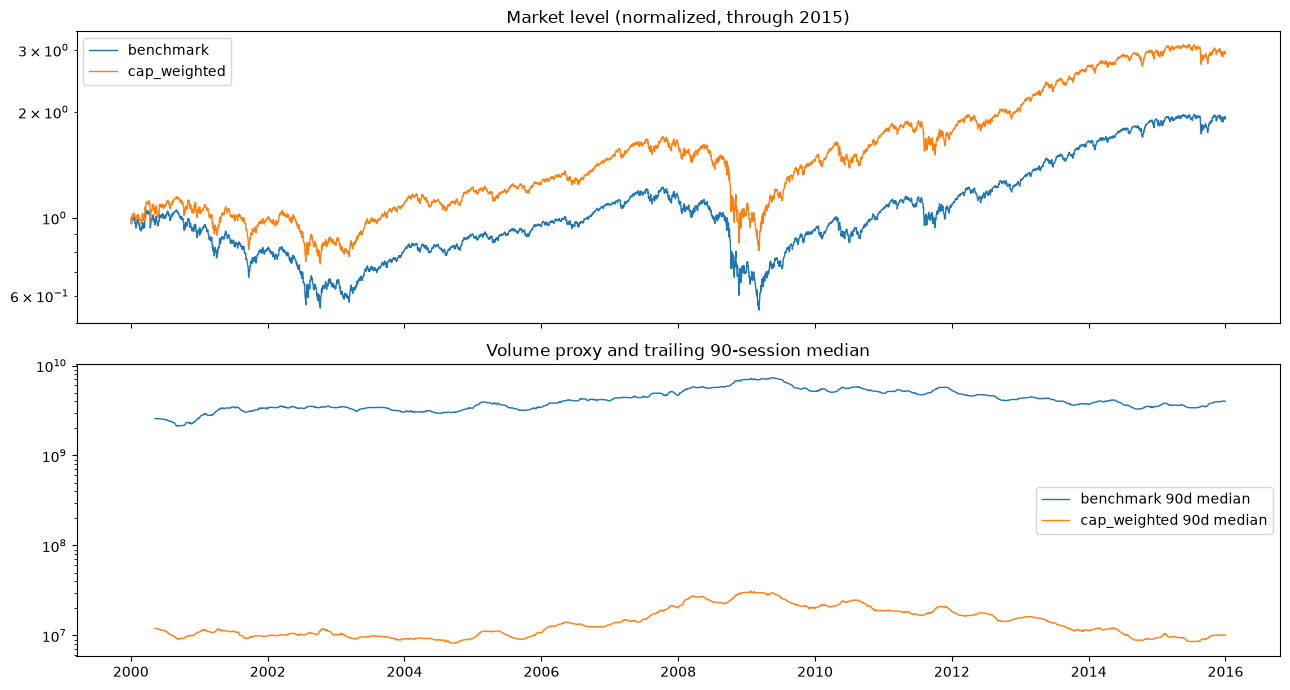

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
for name, series in markets.items():
    price, volume = series.aligned()
    axes[0].plot(price.index, price / price.iloc[0], lw=1, label=name)
    axes[1].plot(volume.index, volume.rolling(90).median(), lw=1, label=f"{name} 90d median")
axes[0].set_title("Market level (normalized, through 2015)")
axes[0].set_yscale("log")
axes[0].legend()
axes[1].set_title("Volume proxy and trailing 90-session median")
axes[1].set_yscale("log")
axes[1].legend()
fig.tight_layout()
plt.show()

## 2. Volume-bar sample

The bucket target is fixed at each bar's start from the trailing 90-session
median. A bar closes when cumulative volume reaches `5 x median`; the bar
return is `log(close_end / close_previous_bar_end)`. Incomplete trailing
buckets are dropped.

This sample is used only by the volume-bar HMM.

In [4]:
bar_sets = {}
rows = []
for name, series in markets.items():
    price, volume = series.aligned()
    bars = volume_bars(
        price,
        volume,
        median_window=CONFIG.median_window,
        bucket_multiple=CONFIG.bucket_multiple,
    )
    bar_sets[name] = bars
    rows.append({
        "market": name,
        "bars": bars.count,
        "median_days": bars.bars.days.median(),
        "mean_days": bars.bars.days.mean(),
        "first_bar": bars.bars.start.iloc[0].date(),
        "last_bar": bars.bars.end.iloc[-1].date(),
        "median_bucket": bars.bars.target.median(),
    })
display(pd.DataFrame(rows))

,market,bars,median_days,mean_days,first_bar,last_bar,median_bucket
0,benchmark,729,5.0,5.390947,2000-05-10,2015-12-22,1.957154e+10
1,cap_weighted,732,5.0,5.377049,2000-05-10,2015-12-31,5.985578e+07


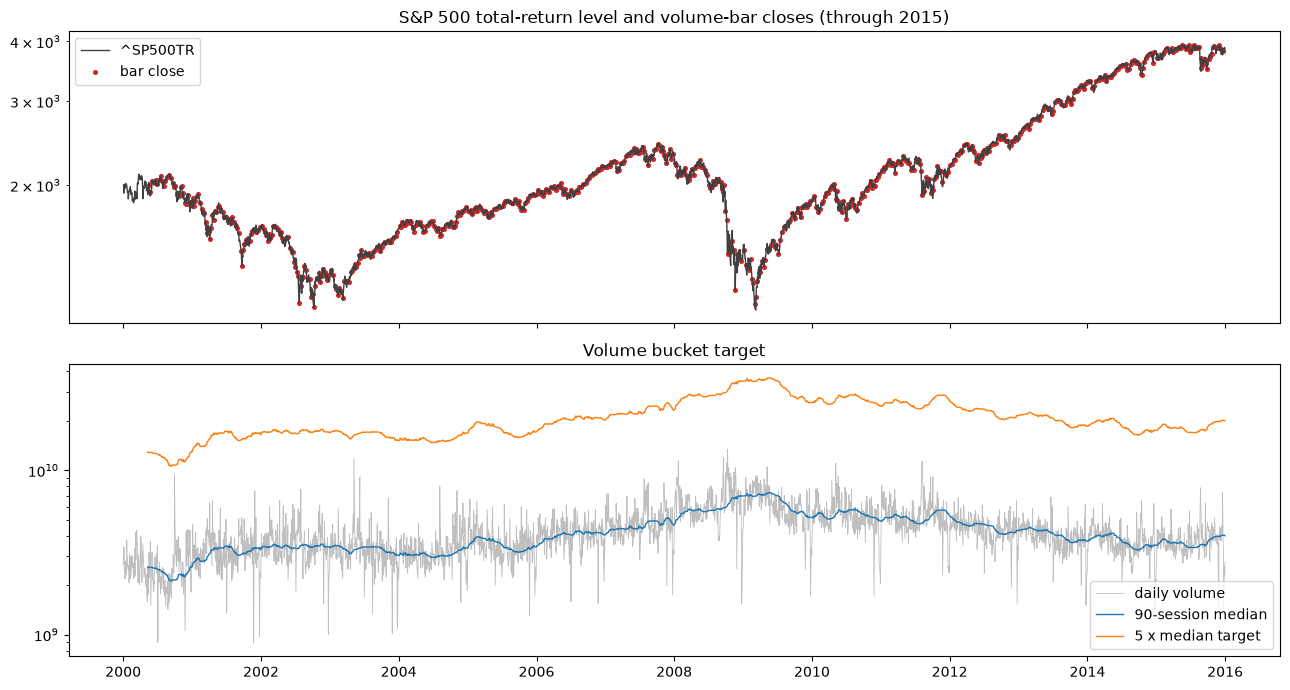

,bar_id,start,end,start_pos,end_pos,base_pos,days,base_price,close_price,log_return,bar_volume,target,median_volume,bucket_multiple
0,0,2000-05-10,2000-05-17,89,94,88,6,1950.50,2000.94,0.025531,1.443088e+10,1.290631e+10,2.581263e+09,5.0
1,1,2000-05-18,2000-05-24,95,99,94,5,2000.94,1933.85,-0.034104,1.417889e+10,1.281338e+10,2.562675e+09,5.0
2,2,2000-05-25,2000-06-02,100,105,99,6,1933.85,2042.79,0.054804,1.514979e+10,1.285828e+10,2.571655e+09,5.0
3,3,2000-06-05,2000-06-13,106,112,105,7,2042.79,2032.58,-0.005011,1.478564e+10,1.277494e+10,2.554988e+09,5.0
4,4,2000-06-14,2000-06-21,113,118,112,6,2032.58,2046.35,0.006752,1.506014e+10,1.265914e+10,2.531827e+09,5.0


In [5]:
bars = bar_sets["benchmark"]
price, volume = markets["benchmark"].aligned()

fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
axes[0].plot(price.index, price, color="0.25", lw=1, label="^SP500TR")
axes[0].scatter(bars.bars.end, bars.bars.close_price, s=7, color="tab:red", label="bar close")
axes[0].set_yscale("log")
axes[0].set_title("S&P 500 total-return level and volume-bar closes (through 2015)")
axes[0].legend()
axes[1].plot(volume.index, volume, color="0.75", lw=0.6, label="daily volume")
axes[1].plot(bars.median_volume.index, bars.median_volume, color="tab:blue", lw=1, label="90-session median")
axes[1].plot(
    bars.median_volume.index,
    CONFIG.bucket_multiple * bars.median_volume,
    color="tab:orange",
    lw=1,
    label="5 x median target",
)
axes[1].set_yscale("log")
axes[1].set_title("Volume bucket target")
axes[1].legend()
fig.tight_layout()
plt.show()
display(bars.bars.head())

## 3. Daily FFD sample

The FFD study uses the native daily log-price sample. It is completely
independent of the volume bars.

The FFD weights follow AFML chapter 5. The ADF regression uses a fixed 20-lag
specification. The diagnostic below is computed on the first 2,000 daily
observations, a pre-development lookback; the walk-forward run re-selects `d`
on its own schedule. This diagnostic is exposition only; it is not an input to
any state series.

diagnostic d = 0.45 on 2000 daily observations


,d,width,observations,pvalue
0,0.00,1,2000,8.495088e-01
1,0.05,3237,0,NaN
2,0.10,4076,0,NaN
3,0.15,3901,0,NaN
4,0.20,3382,0,NaN
5,0.25,2804,0,NaN
6,0.30,2275,0,NaN
7,0.35,1826,175,1.767899e-01
8,0.40,1458,543,5.044221e-02
9,0.45,1163,838,5.772133e-03


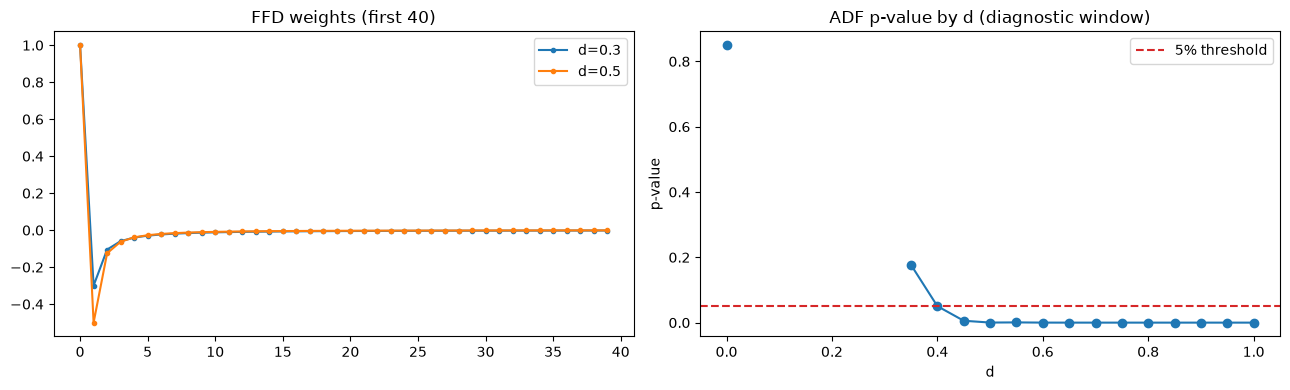

In [6]:
price, _ = markets["benchmark"].aligned()
daily_log_price = pd.Series(np.log(price.to_numpy()), index=price.index, name="log_price")
# Lookback-only diagnostic; no development-window performance is inferred.
diagnostic_end = min(2000, len(daily_log_price))
d0, adf = select_d(
    daily_log_price.to_numpy()[:diagnostic_end],
    CONFIG.ffd_d_grid,
    threshold=CONFIG.ffd_threshold,
    pvalue=CONFIG.ffd_pvalue,
)
print(f"diagnostic d = {d0:.2f} on {diagnostic_end} daily observations")
display(adf)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for d in (0.3, 0.5):
    axes[0].plot(ffd_weights(d, CONFIG.ffd_threshold)[:40], marker="o", ms=3, label=f"d={d}")
axes[0].set_title("FFD weights (first 40)")
axes[0].legend()
axes[1].plot(adf.d, adf.pvalue, marker="o")
axes[1].axhline(CONFIG.ffd_pvalue, color="tab:red", ls="--", label="5% threshold")
axes[1].set_title("ADF p-value by d (diagnostic window)")
axes[1].set_xlabel("d")
axes[1].set_ylabel("p-value")
axes[1].legend()
fig.tight_layout()
plt.show()

## 4. Walk-forward runs

The volume-bar HMM uses `volume_min_train=250` bars (about five years of
weekly bars). The daily FFD HMM uses `ffd_min_train=504` daily observations
(about two years). Each pipeline is refitted and scored independently.

For observation `t`:

1. Fit the 3-state Gaussian HMM on observations strictly before `t`.
2. Score observation `t` with that model.
3. Refit every `refit_every` observations.
4. For FFD, re-select `d` every `d_refit_every` observations using only past
   daily prices.

States are relabelled by emission mean, so state 0 is always the lowest-mean
state and state 2 the highest. Fits before 2010 are warm-up/lookback only.

In [7]:
results = {}
for name, series in markets.items():
    started = time.time()
    results[name] = run_market(series, CONFIG)
    elapsed = time.time() - started
    research = results[name]
    print(
        f"{name}: volume bars={research.volume.bars.count}, "
        f"volume fits={len(research.volume.states.fits)}, "
        f"ffd daily obs={len(research.ffd.states.states)}, "
        f"ffd fits={len(research.ffd.states.fits)}, {elapsed:.1f}s"
    )

benchmark: volume bars=729, volume fits=37, ffd daily obs=4025, ffd fits=47, 32.5s


cap_weighted: volume bars=732, volume fits=38, ffd daily obs=4025, ffd fits=46, 36.4s


## 5. Volume-bar results

The period return is the bar log return. The state sample is the volume-bar
sample only. Displayed states are restricted to the development window
2010-2015; earlier states are lookback/warm-up only.

This is a descriptive summary, not a forecast. The forward 90-day table is the
predictive evaluation.

In [8]:
volume_summary_frames = []
for market, research in results.items():
    dev = development(research.volume.states)
    table = state_summary(
        dev,
        research.volume.bars.bars.set_index("end")["log_return"],
        CONFIG.n_states,
    )
    table.insert(0, "market", market)
    volume_summary_frames.append(table)
volume_summary = pd.concat(volume_summary_frames, ignore_index=True)
display(volume_summary)

,market,state,observations,share,mean_period_return,std_period_return,mean_feature,positive_share
0,benchmark,0,13,0.047273,-0.005560,0.060900,-0.005560,0.538462
1,benchmark,1,133,0.483636,0.002944,0.024466,0.002944,0.578947
2,benchmark,2,129,0.469091,0.003105,0.014668,0.003105,0.620155
3,cap_weighted,0,0,0.000000,NaN,NaN,NaN,NaN
4,cap_weighted,1,90,0.324910,0.002401,0.029737,0.002401,0.633333
5,cap_weighted,2,187,0.675090,0.002603,0.016830,0.002603,0.582888


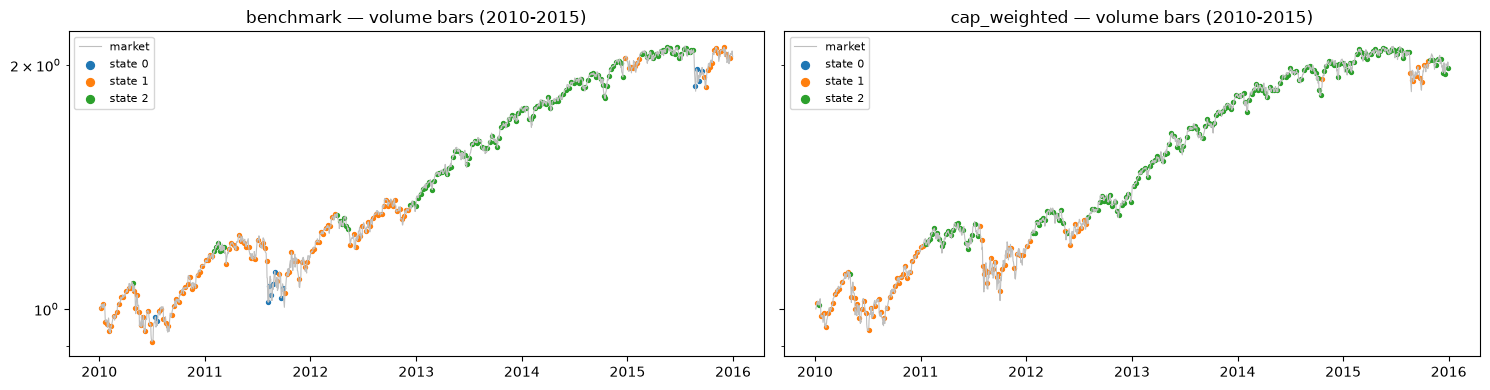

In [9]:
fig, axes = plt.subplots(1, len(results), figsize=(15, 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, (market, research) in zip(axes, results.items()):
    price, _ = markets[market].aligned()
    price = price.loc[DEVELOPMENT_START:DEVELOPMENT_END]
    base = price.iloc[0]
    dev = development(research.volume.states)
    ax.plot(price.index, price / base, color="0.75", lw=0.8, label="market")
    for state in range(CONFIG.n_states):
        dates = dev.states[dev.states.eq(state)].index
        ax.scatter(dates, price.reindex(dates) / base, s=8, label=f"state {state}")
    ax.set_yscale("log")
    ax.set_title(f"{market} — volume bars (2010-2015)")
    ax.legend(markerscale=2, fontsize=8)
fig.tight_layout()
plt.show()

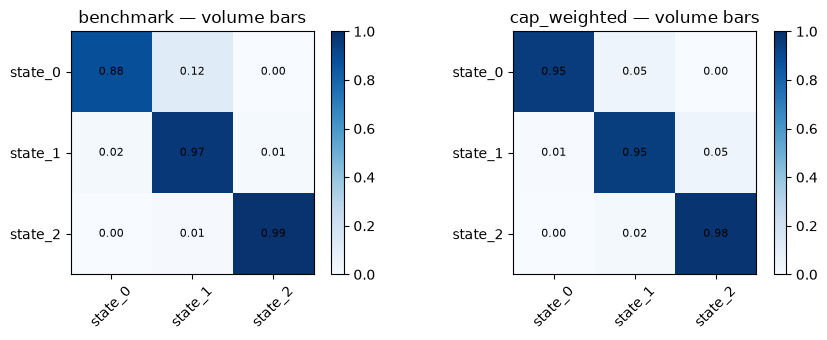

,state,market,count,mean,median,positive_share
0,0,benchmark,13,0.073284,0.073527,1.000000
1,1,benchmark,122,0.030490,0.039540,0.704918
2,2,benchmark,129,0.031871,0.034611,0.829457
3,1,cap_weighted,87,0.056124,0.071157,0.816092
4,2,cap_weighted,179,0.019747,0.026189,0.709497


In [10]:
fig, axes = plt.subplots(1, len(results), figsize=(9, 3.5))
axes = np.atleast_1d(axes)
for ax, (market, research) in zip(axes, results.items()):
    dev = development(research.volume.states)
    matrix = transition_matrix(dev)
    image = ax.imshow(matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=45)
    ax.set_yticks(range(len(matrix)), matrix.index)
    ax.set_title(f"{market} — volume bars")
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

volume_forward_frames = []
for market, research in results.items():
    dev = development(research.volume.states)
    price, _ = markets[market].aligned()
    forward = forward_return(price, dev.states.index, days=90)
    frame = pd.concat([dev.states.rename("state"), forward], axis=1).dropna()
    frame = frame.loc[frame["state"] >= 0]
    grouped = frame.groupby("state")["forward_90d"]
    table = grouped.agg(["count", "mean", "median"])
    table["positive_share"] = grouped.apply(lambda values: (values > 0).mean())
    table.insert(0, "market", market)
    volume_forward_frames.append(table.reset_index())
volume_forward = pd.concat(volume_forward_frames, ignore_index=True)
display(volume_forward)

## 6. Daily FFD results

The period return is the daily log return. The state sample is the daily FFD
sample only; it is not aligned to the volume bars. Displayed states are
restricted to 2010-2015.

The `d` panel shows the value in force over the development window. Because
the 2016 buffer is excluded, some late-2015 forward 90-day rows are undefined.

This is a descriptive summary; the forward 90-day table is the predictive
evaluation.

,market,state,observations,share,mean_period_return,std_period_return,mean_feature,positive_share
0,benchmark,0,41,0.027152,-0.003841,0.028392,0.172656,0.390244
1,benchmark,1,197,0.130464,-0.002941,0.014215,0.315911,0.441624
2,benchmark,2,1272,0.842384,0.001155,0.007767,0.533461,0.575472
3,cap_weighted,0,89,0.063300,-0.002125,0.022653,0.117480,0.438202
4,cap_weighted,1,248,0.176387,-0.001858,0.012293,0.083308,0.447581
5,cap_weighted,2,1069,0.760313,0.001219,0.007902,0.085431,0.579981


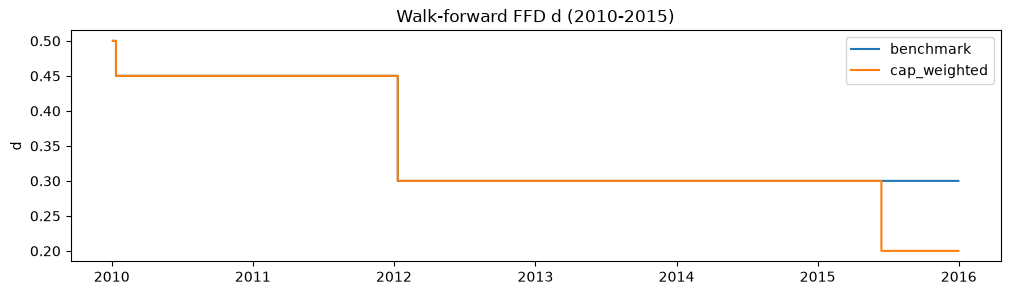

In [11]:
ffd_summary_frames = []
for market, research in results.items():
    dev = development(research.ffd.states)
    daily_returns = research.ffd.daily_log_price.diff().rename("daily_return")
    table = state_summary(dev, daily_returns, CONFIG.n_states)
    table.insert(0, "market", market)
    ffd_summary_frames.append(table)
ffd_summary = pd.concat(ffd_summary_frames, ignore_index=True)
display(ffd_summary)

fig, ax = plt.subplots(figsize=(12, 3))
for market, research in results.items():
    d = development(research.ffd.states).d.dropna()
    ax.step(d.index, d, where="post", label=market)
ax.set_title("Walk-forward FFD d (2010-2015)")
ax.set_ylabel("d")
ax.legend()
plt.show()

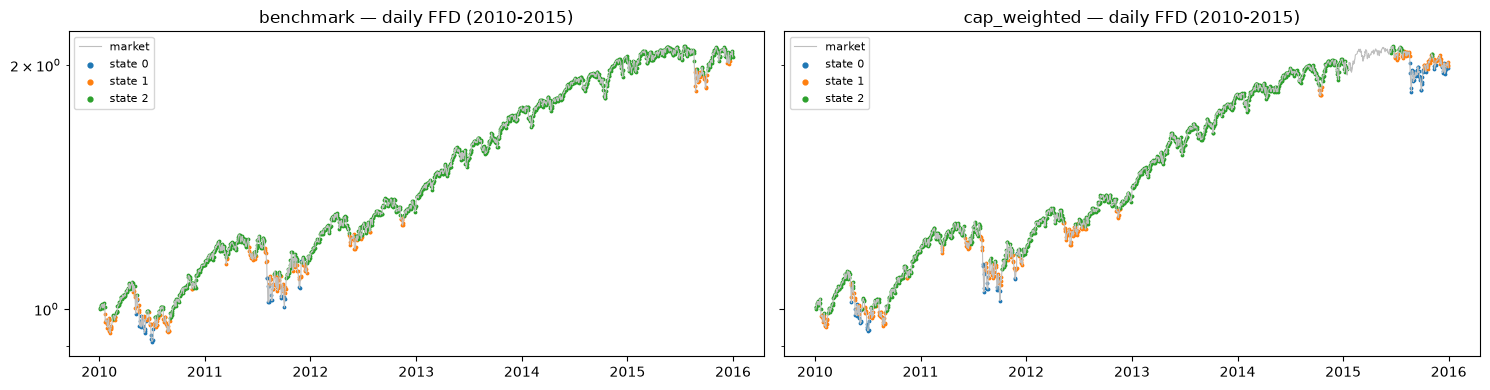

In [12]:
fig, axes = plt.subplots(1, len(results), figsize=(15, 4), sharey=True)
axes = np.atleast_1d(axes)
for ax, (market, research) in zip(axes, results.items()):
    price, _ = markets[market].aligned()
    price = price.loc[DEVELOPMENT_START:DEVELOPMENT_END]
    base = price.iloc[0]
    dev = development(research.ffd.states)
    ax.plot(price.index, price / base, color="0.75", lw=0.8, label="market")
    for state in range(CONFIG.n_states):
        dates = dev.states[dev.states.eq(state)].index
        ax.scatter(dates, price.reindex(dates) / base, s=3, label=f"state {state}")
    ax.set_yscale("log")
    ax.set_title(f"{market} — daily FFD (2010-2015)")
    ax.legend(markerscale=2, fontsize=8)
fig.tight_layout()
plt.show()

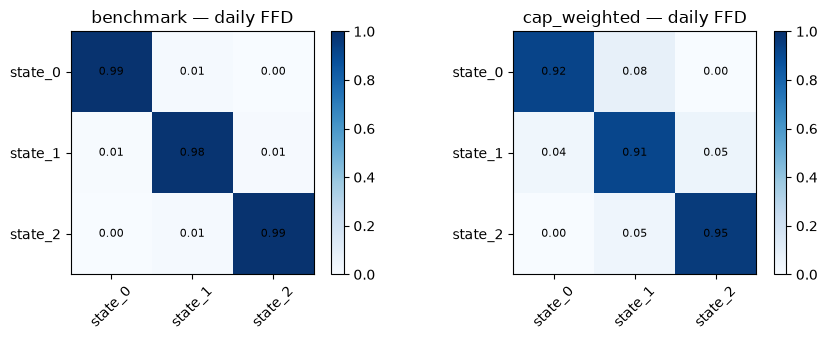

,state,market,count,mean,median,positive_share
0,0,benchmark,41,0.060419,0.057572,0.731707
1,1,benchmark,192,0.060823,0.076037,0.807292
2,2,benchmark,1214,0.027683,0.033438,0.753707
3,0,cap_weighted,68,0.050895,0.043346,0.838235
4,1,cap_weighted,209,0.055341,0.070377,0.736842
5,2,cap_weighted,1066,0.028431,0.035112,0.760788


In [13]:
fig, axes = plt.subplots(1, len(results), figsize=(9, 3.5))
axes = np.atleast_1d(axes)
for ax, (market, research) in zip(axes, results.items()):
    dev = development(research.ffd.states)
    matrix = transition_matrix(dev)
    image = ax.imshow(matrix.to_numpy(), cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(matrix)), matrix.columns, rotation=45)
    ax.set_yticks(range(len(matrix)), matrix.index)
    ax.set_title(f"{market} — daily FFD")
    for i in range(len(matrix)):
        for j in range(len(matrix)):
            ax.text(j, i, f"{matrix.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
plt.show()

ffd_forward_frames = []
for market, research in results.items():
    dev = development(research.ffd.states)
    price, _ = markets[market].aligned()
    forward = forward_return(price, dev.states.index, days=90)
    frame = pd.concat([dev.states.rename("state"), forward], axis=1).dropna()
    frame = frame.loc[frame["state"] >= 0]
    grouped = frame.groupby("state")["forward_90d"]
    table = grouped.agg(["count", "mean", "median"])
    table["positive_share"] = grouped.apply(lambda values: (values > 0).mean())
    table.insert(0, "market", market)
    ffd_forward_frames.append(table.reset_index())
ffd_forward = pd.concat(ffd_forward_frames, ignore_index=True)
display(ffd_forward)

## 7. Lookahead audit

The model inputs are causal:

- `walk_forward_states` fits at observation `t` on `values[:t]`; observation `t`
  is only scored.
- `walk_forward_ffd_states` selects `d` from `daily[:t]` and fits on
  `features[:t]`; day `t` is only scored.
- FFD is a causal convolution; a future-price perturbation leaves past FFD
  values unchanged.
- Volume bars use trailing volume only; future price or volume changes do not
  alter earlier bars.
- Forward 90-day returns are evaluation-only and never enter a fit or a state
  decision.

`tests/test_research.py` checks these properties at the component and pipeline
levels, including a test that perturbs future prices and volume and asserts
that earlier states are unchanged.

## 8. Comparison and limits

The two forward tables are directly comparable as diagnostics, but they are
not the same sample:

- volume-bar states are evaluated on bar-end dates;
- daily FFD states are evaluated every session.

The 90-day forward windows overlap, so the observations are not independent.
The best state is not selected here; that belongs to the strategy step.

All displayed and saved research results are restricted to the development
window 2010-2015. The 2016 Q1 buffer is excluded from fitting and research,
and the 2016-04-01+ final test is reserved for a separate frozen-model run.

Limitations: HMM states are statistical regimes, not economic labels; local
optima are possible; the cap-weighted series is a proxy; and this notebook
does not yet include transaction costs or the final out-of-sample strategy
run.

Adjusted prices follow the course data convention and may embed future split or
dividend adjustments; that is a data-vintage limitation, not a model-fit
lookahead. The walk-forward loop itself only uses observations before each
state date.

## 9. Saved outputs

The CSVs below are the hand-off to strategy 2. The two state files come from
independent samples and should not be joined as if they were one bar table.

The state files contain only the development window 2010-2015. No 2016+ row is
written. The bar file contains the full 2000-2015 lookback history for
reproducibility.

In [14]:
manifest = []
for market, research in results.items():
    bars_path = OUTPUT / f"{market}_bars.csv"
    research.volume.bars.bars.to_csv(bars_path, index=False)
    manifest.append(bars_path)

    volume_dev = development(research.volume.states)
    volume_frame = pd.concat(
        [
            volume_dev.states.rename("state"),
            volume_dev.probabilities,
            volume_dev.versions.rename("model_version"),
            volume_dev.feature.rename("feature"),
        ],
        axis=1,
    )
    volume_path = OUTPUT / f"{market}_volume_states.csv"
    volume_frame.to_csv(volume_path)
    manifest.append(volume_path)

    ffd_dev = development(research.ffd.states)
    ffd_frame = pd.concat(
        [
            ffd_dev.states.rename("state"),
            ffd_dev.probabilities,
            ffd_dev.versions.rename("model_version"),
            ffd_dev.feature.rename("feature"),
            ffd_dev.d.rename("d"),
        ],
        axis=1,
    )
    ffd_path = OUTPUT / f"{market}_ffd_daily_states.csv"
    ffd_frame.to_csv(ffd_path)
    manifest.append(ffd_path)

volume_summary.to_csv(OUTPUT / "volume_state_summary.csv", index=False)
ffd_summary.to_csv(OUTPUT / "ffd_state_summary.csv", index=False)
volume_forward.to_csv(OUTPUT / "forward_90d_volume.csv", index=False)
ffd_forward.to_csv(OUTPUT / "forward_90d_ffd.csv", index=False)

config_path = OUTPUT / "config.json"
config_path.write_text(
    json.dumps(
        {
            "database": str(DATABASE.relative_to(root)),
            "end": END,
            "development_start": DEVELOPMENT_START,
            "development_end": DEVELOPMENT_END,
            "buffer_start": BUFFER_START,
            "buffer_end": BUFFER_END,
            "final_test_start": FINAL_TEST_START,
            "median_window": CONFIG.median_window,
            "bucket_multiple": CONFIG.bucket_multiple,
            "volume_min_train": CONFIG.volume_min_train,
            "volume_refit_every": CONFIG.volume_refit_every,
            "ffd_min_train": CONFIG.ffd_min_train,
            "ffd_refit_every": CONFIG.ffd_refit_every,
            "ffd_d_refit_every": CONFIG.ffd_d_refit_every,
            "n_states": CONFIG.n_states,
            "n_init": CONFIG.n_init,
            "seed": CONFIG.seed,
            "n_iter": CONFIG.n_iter,
            "ffd_threshold": CONFIG.ffd_threshold,
            "ffd_pvalue": CONFIG.ffd_pvalue,
        },
        indent=2,
    )
)
manifest.append(config_path)
manifest.extend([
    OUTPUT / "volume_state_summary.csv",
    OUTPUT / "ffd_state_summary.csv",
    OUTPUT / "forward_90d_volume.csv",
    OUTPUT / "forward_90d_ffd.csv",
])

display(
    pd.DataFrame(
        {
            "file": [path.name for path in manifest],
            "bytes": [path.stat().st_size for path in manifest],
        }
    )
)

,file,bytes
0,benchmark_bars.csv,90633
1,benchmark_volume_states.csv,26899
2,benchmark_ffd_daily_states.csv,154093
3,cap_weighted_bars.csv,117063
4,cap_weighted_volume_states.csv,27154
5,cap_weighted_ffd_daily_states.csv,146910
6,config.json,565
7,volume_state_summary.csv,720
8,ffd_state_summary.csv,812
9,forward_90d_volume.csv,412


## 10. Pairs_Tilt (third model)

This section is independent of the HMM study. `Pairs_Tilt` is a long-only
relative-value model:

- common clock: the cap-weighted eligible universe's volume bars close at
  **10x** the trailing 90-session median daily volume;
- Ward clusters on `log ME, BM, OP, INV` (no current-sector dummies);
- Engle-Granger ADF within each cluster, FDR-adjusted, with a Kalman
  random-walk hedge ratio and a spread z-score;
- cheap leg only; the expensive leg is not purchased;
- cointegration is rescanned every **30 calendar days** on the latest completed
  volume bar, with at most seven clusters; selected pairs and hedge ratios are
  frozen until the next rebalance;
- three overlapping **30-day** sleeves, each held 90 days; the first three
  decisions are cap-weighted market, then each maturity rotates into the
  strongest pairs with unused capital in the market.

The submission notebook (`Backtesting.ipynb`) applies the same cadence to a
screened top-500 market-cap universe; this section keeps a liquid 45-name
illustration subset so the research cell stays quick.

Development-period demonstration only. `PAIR_RUN_START` is inside 2010-2015,
`END` is 2015-12-31, and no 2016+ row is loaded. The final test is separate.

In [15]:
from backtesting import Backtester, FamaFrench5, MarketData
from research.pairs import PairsConfig, PairsResearch
from strategies import PairsTiltStrategy

PAIR_SYMBOLS = [  # liquid development universe; set None for the full database
    "AAPL", "MSFT", "AMZN", "JPM", "XOM", "JNJ", "PG", "KO", "WMT", "DIS",
    "CSCO", "INTC", "IBM", "CVX", "PFE", "MRK", "ABT", "T", "VZ", "ORCL",
    "BAC", "WFC", "C", "GS", "MS", "AXP", "HD", "MCD", "NKE", "CAT",
    "BA", "GE", "MMM", "HON", "UNH", "CVS", "LLY", "BMY", "AMGN", "GILD",
    "QCOM", "TXN", "MU", "ADI", "EBAY",
]
PAIR_RUN_START = "2013-01-02"  # development-period demonstration only

pair_data = MarketData.load(DATABASE, end=END, symbols=PAIR_SYMBOLS)
pair_factors = FamaFrench5(lag_months=6).build(
    pair_data, start="2005-01-01", end=END)
pair_config = PairsConfig(
    rebalance_days=30,
    max_clusters=7,
    candidate_pairs_per_cluster=20,
    pair_lookback_bars=104,
    min_history_bars=60,
    silhouette_sample=200,
)
pair_result = PairsResearch(pair_config).build(
    pair_data, pair_factors, start="2005-01-01", end=END)

print("research cutoff:", END)
print(pair_config)
print("bars:", len(pair_result.bar_clock.bars),
      "cluster dates:", pair_result.clusters.date.nunique() if len(pair_result.clusters) else 0,
      "pair signals:", len(pair_result.signals))
display(pair_result.coverage.tail())
display(pair_result.signals.tail())

research cutoff: 2015-12-31
PairsConfig(bar_median_window=90, bar_multiple=10.0, cluster_refresh_bars=13, min_cluster_size=5, min_clusters=5, max_clusters=25, silhouette_sample=500, pair_lookback_bars=104, min_history_bars=60, candidate_pairs_per_cluster=20, max_pairs_per_cluster=3, adf_pvalue=0.05, min_half_life=2.0, max_half_life=26.0, entry_z=2.0, max_stale_bars=0, kalman_process_var=1e-06, kalman_obs_var=0.001, sector_dummies=False)
bars: 268 cluster dates: 21 pair signals: 3


,date,universe,clusters,pairs_tested,pairs_eligible
263,2015-10-23,44,3,60,0
264,2015-11-06,44,3,60,0
265,2015-11-24,44,3,60,0
266,2015-12-11,44,3,60,0
267,2015-12-29,44,3,60,0


,date,pair_id,leg_a,leg_b,long_symbol,cluster,beta,alpha,zscore,adf_p,adf_p_adj,half_life,correlation
0,2008-10-29,BAC|PFE,BAC,PFE,BAC,1,1.442550,-0.011544,-2.188850,0.000153,0.006129,2.099124,0.546162
1,2008-11-24,BAC|MS,BAC,MS,BAC,1,0.562217,1.406016,-2.671161,0.000119,0.004745,2.488120,0.678917
2,2009-03-30,BAC|MS,BAC,MS,BAC,1,0.929146,0.065693,-3.515954,0.000603,0.024119,23.345114,0.534283


In [16]:
pair_strategy = PairsTiltStrategy(
    pair_result, pair_factors, max_pairs=3, sleeve_days=30, ramp_sleeves=3)
pair_engine = Backtester(
    market_data=pair_data,
    strategy=pair_strategy,
    initial_cash=1_000_000,
    fee_bps=5,
    delisting="error",
)
pair_backtest = pair_engine.run(PAIR_RUN_START, END)
display(pair_backtest.performance())
display(pair_backtest.fills.head())
display(pair_backtest.pnl)
display(pair_backtest.coverage)

,Strategy,S&P 500 total return
final_value,1.412465e+06,1.487843e+06
total_return,4.124647e-01,4.878433e-01
CAGR,1.220876e-01,1.417170e-01
max_drawdown,-1.349206e-01,-1.203650e-01
Sharpe,8.234597e-01,9.493708e-01
annualized_volatility,1.252996e-01,1.272053e-01
annualized_alpha,-1.246262e-02,0.000000e+00
beta,9.575766e-01,1.000000e+00
VaR_95_daily,1.345993e-02,1.351713e-02
VaR_99_daily,2.012619e-02,2.097776e-02


,order_id,lot_id,strategy_id,trigger,model_version,symbol,side,signal_date,date,due_date,price,units,notional,fee,cash_change,realized_pnl
0,0,0,Pairs_Tilt,strategy,0,AAPL,BUY,2012-12-31,2013-01-02,2013-04-02,16.58,608.910741,10095.740093,5.047870,-10100.787963,0.0
1,1,1,Pairs_Tilt,strategy,0,ABT,BUY,2012-12-31,2013-01-02,2013-04-02,24.73,42.143902,1042.218687,0.521109,-1042.739796,0.0
2,2,2,Pairs_Tilt,strategy,0,ADI,BUY,2012-12-31,2013-01-02,2013-04-02,33.07,8.232911,272.262356,0.136131,-272.398488,0.0
3,3,3,Pairs_Tilt,strategy,0,AMGN,BUY,2012-12-31,2013-01-02,2013-04-02,65.08,21.636800,1408.122942,0.704061,-1408.827004,0.0
4,4,4,Pairs_Tilt,strategy,0,AMZN,BUY,2012-12-31,2013-01-02,2013-04-02,12.87,187.015828,2406.893701,1.203447,-2408.097148,0.0


realized      341103.493998
unrealized     71361.171154
total         412464.665151
dtype: float64

requested_start         2013-01-02 00:00:00
requested_end           2015-12-31 00:00:00
effective_start         2013-01-02 00:00:00
effective_end           2015-12-31 00:00:00
initial_capital_date    2012-12-31 00:00:00
range_clipped                         False
dtype: object